In [1]:
import numpy as np
import pandas as pd

forecast = pd.read_parquet(
    "data/model_ready/final_forecast_d1914_d1941.parquet"
)

forecast["error"] = forecast["predicted_sales"] - forecast["actual_sales"]
forecast["absolute_error"] = forecast["error"].abs()
forecast["squared_error"] = forecast["error"] ** 2

daily = forecast.groupby("d").agg(
    MAE=("absolute_error", "mean"),
    MSE=("squared_error", "mean"),
    absolute_error_sum=("absolute_error", "sum"),
    actual_sales_sum=("actual_sales", lambda s: s.abs().sum()),
    Bias=("error", "mean"),
)

daily["RMSE"] = np.sqrt(daily.pop("MSE"))
daily["WAPE_%"] = 100 * daily.pop("absolute_error_sum") / daily.pop("actual_sales_sum")

print(daily.round(3).to_string())

          MAE   Bias   RMSE     WAPE_%
d                                     
d_1914  0.946  0.011  1.944  74.338997
d_1915  0.905  0.056  1.749  77.755997
d_1916  0.914  0.068  1.789  80.927002
d_1917  0.919  0.065  1.764  80.689003
d_1918  1.019 -0.086  2.138  72.429001
d_1919  1.132 -0.125  2.348  68.417000
d_1920  1.162 -0.138  2.307  66.821999
d_1921  1.034 -0.111  2.143  72.996002
d_1922  1.057 -0.177  2.329  72.746002
d_1923  1.008 -0.085  2.146  77.642998
d_1924  1.020 -0.097  2.128  76.297997
d_1925  1.071 -0.106  2.467  74.539001
d_1926  1.223 -0.248  2.810  68.776001
d_1927  1.136  0.045  2.473  75.945000
d_1928  1.105 -0.257  2.504  72.595001
d_1929  1.005 -0.122  2.080  77.843002
d_1930  1.054 -0.246  2.430  76.068001
d_1931  1.020 -0.198  2.152  76.806999
d_1932  1.079 -0.246  2.281  74.672997
d_1933  1.236 -0.390  2.829  69.366997
d_1934  1.336 -0.550  3.062  67.964996
d_1935  1.044 -0.302  2.205  75.153999
d_1936  0.987 -0.246  2.054  77.613998
d_1937  0.954 -0.227  1.9

In [2]:
import numpy as np
import pandas as pd

forecast = pd.read_parquet(
    "data/model_ready/final_forecast_d1914_d1941.parquet"
)

# Derive category and store from IDs such as FOODS_1_001_CA_1_evaluation
parts = forecast["id"].str.split("_")
forecast["category"] = parts.str[0]
forecast["store"] = parts.str[-3] + "_" + parts.str[-2]

forecast["error"] = forecast["predicted_sales"] - forecast["actual_sales"]
forecast["absolute_error"] = forecast["error"].abs()

def summarize(group):
    error = group["error"]
    actual = group["actual_sales"]
    return pd.Series({
        "MAE": group["absolute_error"].mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
        "WAPE_%": 100 * group["absolute_error"].sum() / actual.abs().sum(),
        "Bias": error.mean(),
    })

print("By category:")
print(forecast.groupby("category").apply(summarize).round(3))

print("\nBy store:")
print(forecast.groupby("store").apply(summarize).round(3))

By category:
             MAE   RMSE      WAPE_%   Bias
category                                  
FOODS      1.377  2.927   66.575996 -0.341
HOBBIES    0.768  1.663  104.832001 -0.020
HOUSEHOLD  0.793  1.440   82.033997 -0.077

By store:
         MAE   RMSE     WAPE_%   Bias
store                                
CA_1   1.154  2.311  73.533997 -0.198
CA_2   1.152  2.145  73.973999 -0.209
CA_3   1.370  3.026  66.711998 -0.243
CA_4   0.818  1.466  88.570000 -0.081
TX_1   0.896  1.870  78.427002 -0.134
TX_2   1.003  2.110  74.266998 -0.190
TX_3   1.022  2.193  74.853996 -0.236
WI_1   0.991  1.768  75.226997 -0.152
WI_2   1.246  3.269  69.079002 -0.304
WI_3   0.986  2.194  73.311996 -0.162


In [3]:
import numpy as np
import pandas as pd

# Load the saved forecast if `forecast` isn't already available
forecast = pd.read_parquet(
    "data/model_ready/final_forecast_d1914_d1941.parquet"
)

foods3 = forecast[forecast["id"].str.startswith("FOODS_3_")].copy()
foods3["error"] = foods3["predicted_sales"] - foods3["actual_sales"]
foods3["absolute_error"] = foods3["error"].abs()

by_series = foods3.groupby("id").agg(
    days=("d", "nunique"),
    actual_sales=("actual_sales", "sum"),
    total_absolute_error=("absolute_error", "sum"),
    MAE=("absolute_error", "mean"),
    Bias=("error", "mean"),
)

by_series["WAPE_%"] = np.where(
    by_series["actual_sales"] != 0,
    100 * by_series["total_absolute_error"] / by_series["actual_sales"].abs(),
    np.nan,
)
by_series["share_of_foods3_error_%"] = (
    100 * by_series["total_absolute_error"]
    / by_series["total_absolute_error"].sum()
)

print(
    by_series.sort_values("total_absolute_error", ascending=False)
    .head(20)
    .round(3)
    .to_string()
)

                             days  actual_sales  total_absolute_error        MAE       Bias      WAPE_%  share_of_foods3_error_%
id                                                                                                                              
FOODS_3_090_CA_3_evaluation    28        3357.0           1944.675049  69.453003 -69.453003   57.929001                    0.555
FOODS_3_234_WI_2_evaluation    28        1089.0            962.010010  34.356998 -29.049999   88.338997                    0.275
FOODS_3_586_TX_2_evaluation    28        2285.0            898.418030  32.085999 -31.159000   39.318001                    0.257
FOODS_3_444_WI_2_evaluation    28         855.0            852.901978  30.461000 -30.384001   99.754997                    0.244
FOODS_3_362_CA_3_evaluation    28         313.0            821.012024  29.322001  29.322001  262.303986                    0.234
FOODS_3_090_WI_3_evaluation    28        2066.0            817.693970  29.202999 -20.110001   39.

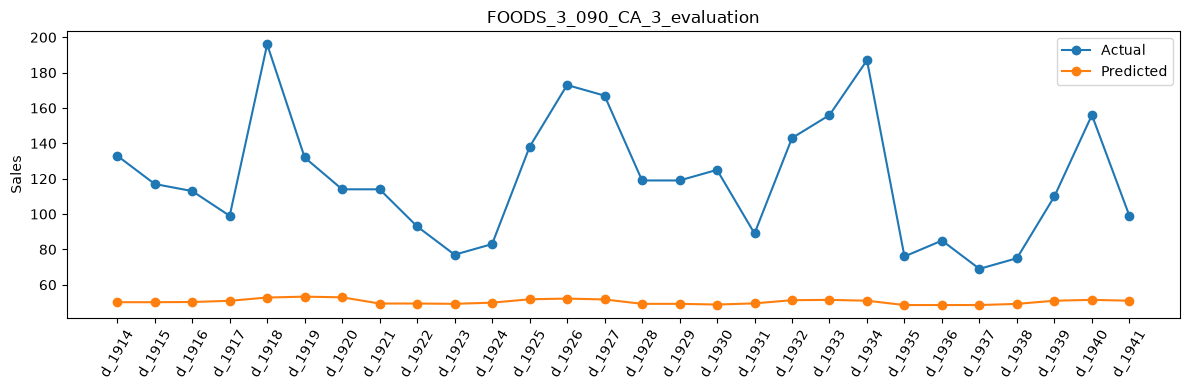

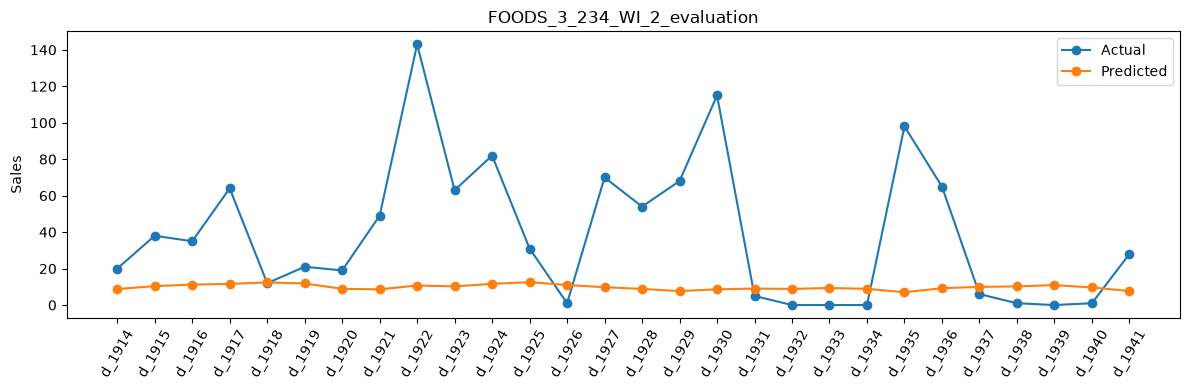

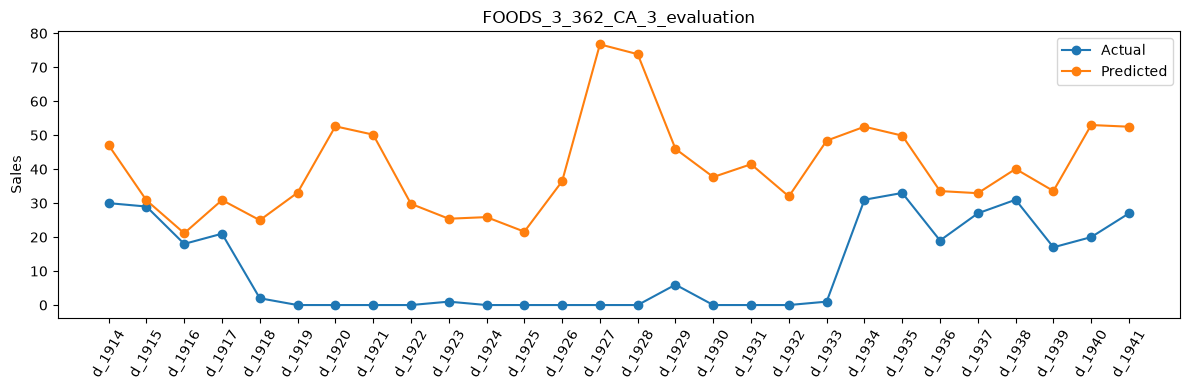

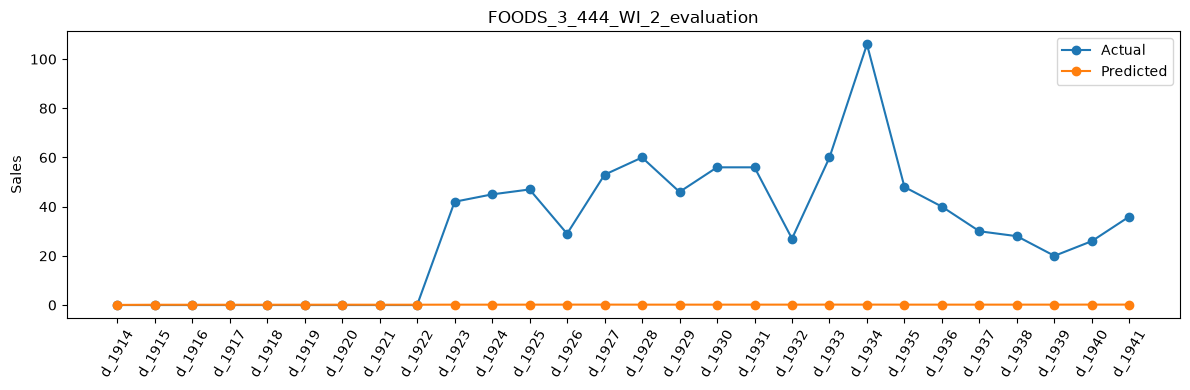

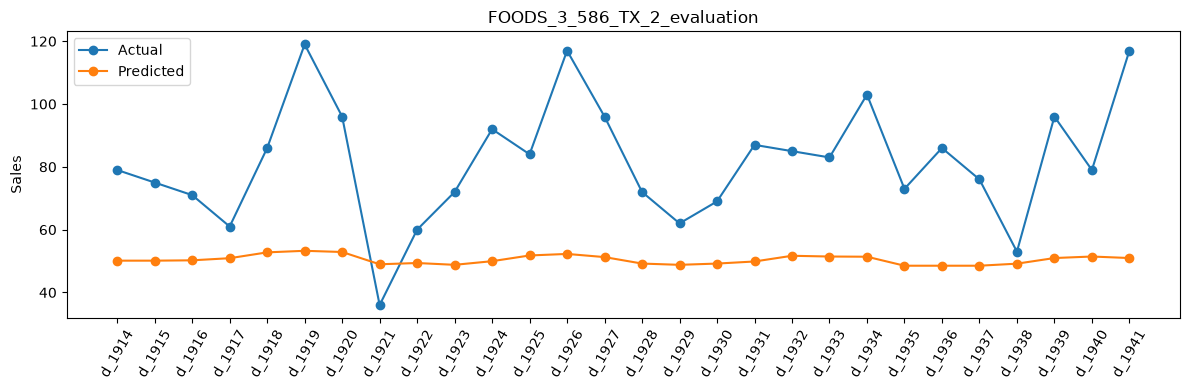

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

forecast = pd.read_parquet(
    "data/model_ready/final_forecast_d1914_d1941.parquet"
)

foods3 = forecast[forecast["id"].str.startswith("FOODS_3_")].copy()
foods3["absolute_error"] = (
    foods3["predicted_sales"] - foods3["actual_sales"]
).abs()

top_ids = (
    foods3.groupby("id")["absolute_error"]
    .sum()
    .nlargest(5)
    .index
)

top_items = foods3[foods3["id"].isin(top_ids)]

for item_id, group in top_items.groupby("id"):
    group = group.sort_values("d")
    plt.figure(figsize=(12, 4))
    plt.plot(group["d"], group["actual_sales"], marker="o", label="Actual")
    plt.plot(group["d"], group["predicted_sales"], marker="o", label="Predicted")
    plt.title(item_id)
    plt.xticks(rotation=60)
    plt.ylabel("Sales")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [5]:
import numpy as np
import pandas as pd

forecast = pd.read_parquet(
    "data/model_ready/final_forecast_d1914_d1941.parquet"
)

# Use only the 28 days before the forecast as baseline history
history_days = [f"d_{day}" for day in range(1886, 1914)]
history = pd.read_csv(
    "data/raw/sales_train_evaluation.csv",
    usecols=["id"] + history_days,
)

# Focus on the five series with the largest FOODS_3 errors
foods3 = forecast[forecast["id"].str.startswith("FOODS_3_")].copy()
foods3["abs_error"] = (
    foods3["predicted_sales"] - foods3["actual_sales"]
).abs()
top_ids = foods3.groupby("id")["abs_error"].sum().nlargest(5).index

history = history[history["id"].isin(top_ids)].set_index("id")
baseline = history.mean(axis=1).rename("baseline_28d")

compare = (
    forecast[forecast["id"].isin(top_ids)]
    .join(baseline, on="id")
)

def metrics(group, prediction_col):
    error = group[prediction_col] - group["actual_sales"]
    return pd.Series({
        "MAE": error.abs().mean(),
        "WAPE_%": 100 * error.abs().sum() / group["actual_sales"].abs().sum(),
        "Bias": error.mean(),
    })

for item_id, group in compare.groupby("id"):
    print(f"\n{item_id}")
    print(pd.DataFrame({
        "XGBoost": metrics(group, "predicted_sales"),
        "28-day average": metrics(group, "baseline_28d"),
    }).round(3))


FOODS_3_090_CA_3_evaluation
          XGBoost  28-day average
MAE     69.453003          28.031
WAPE_%  57.929001          23.380
Bias   -69.453003          -9.536

FOODS_3_234_WI_2_evaluation
          XGBoost  28-day average
MAE     34.356998          34.615
WAPE_%  88.338997          89.000
Bias   -29.049999         -29.714

FOODS_3_362_CA_3_evaluation
           XGBoost  28-day average
MAE      29.322001          27.321
WAPE_%  262.303986         244.409
Bias     29.322001          27.321

FOODS_3_444_WI_2_evaluation
          XGBoost  28-day average
MAE     30.461000          30.536
WAPE_%  99.754997         100.000
Bias   -30.384001         -30.536

FOODS_3_586_TX_2_evaluation
          XGBoost  28-day average
MAE     32.085999          15.036
WAPE_%  39.318001          18.425
Bias   -31.159000          -5.607
